# Week 1 — Uber Movement Data Exploration

This notebook documents the **data-understanding and validation process** for the historical batch source used by the Urban Mobility Lambda/Lakehouse project.

The supplied archive contains seven city-level Uber Movement travel-time exports. These are **aggregated zone-to-zone travel-time statistics**, not billions of raw trip records. Week 1 therefore focuses on:

1. discovering and validating the files;
2. understanding the OD structure and time coverage;
3. measuring route-level travel-time variability;
4. checking the lower/mean/upper relationship used by the synthetic simulator;
5. inspecting geographic distance relationships where geometry exists;
6. producing a clean contract for Week 2 Spark ingestion.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents) if (parent / 'src' / 'urban_mobility').is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate the project root. Start Jupyter from this repository or a subdirectory.')

sys.path.insert(0, str(REPO_ROOT / 'src'))

from urban_mobility.analysis.profiling import build_location_summary, build_profile, write_artifacts
from urban_mobility.data.loader import discover_csv_files, enrich_routes, load_dataset

DATA_DIR = REPO_ROOT / 'data' / 'raw' / 'uber_movement'
FIGURE_DIR = REPO_ROOT / 'artifacts' / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
print('Dataset directory:', DATA_DIR)

Dataset directory: C:\Users\Theguywhovanish\Documents\Study\Big Data\Traffic-Density-Prediction\data\raw\uber_movement


## 1. File inventory

First, inspect the real files instead of assuming a single `Travel_Times.csv`. Location is inferred from filenames such as `Travel_Times - Boston.csv`.


In [2]:
files = discover_csv_files(DATA_DIR)
file_inventory = pd.DataFrame({
    'file': [p.name for p in files],
    'size_kb': [round(p.stat().st_size / 1024, 1) for p in files],
})
file_inventory


,file,size_kb
0,Travel_Times - Bogota.csv,1516.5
1,Travel_Times - Boston.csv,988.0
2,Travel_Times - Johannesburg and Pretoria.csv,36.7
3,Travel_Times - Manila.csv,332.3
4,Travel_Times - Paris.csv,327.0
5,Travel_Times - Sydney.csv,590.9
6,Travel_Times - Washington DC.csv,4248.1


## 2. Canonical loading and data-quality checks

The loader preserves names/geometries when available and normalizes the core contract to `location + origin_id + destination_id + M/L/U`.


In [3]:
raw_routes, file_profile = load_dataset(DATA_DIR)
routes = enrich_routes(raw_routes)
profile = build_profile(routes, file_profile, DATA_DIR)

print(pd.Series(profile).to_string())
print() 
print('Per-file validation:')
display(file_profile[['source_file','location','status','rows_raw','rows_valid','rows_invalid','unique_origins','unique_destinations']])


source                                C:\Users\Theguywhovanish\Documents\Study\Big D...
files_discovered                                                                      7
files_processed                                                                       7
rows_raw                                                                           5547
rows_valid                                                                         5547
rows_invalid                                                                          0
rows_after_dedup                                                                   5547
unique_locations                                                                      7
unique_od_keys                                                                     5547
all_bounds_ordered                                                                 True
log_symmetric_within_1pct_pct                                                 99.873806
median_log_symmetry_relative_err

,source_file,location,status,rows_raw,rows_valid,rows_invalid,unique_origins,unique_destinations
0,Travel_Times - Bogota.csv,Bogota,processed,496,496,0,1,496
1,Travel_Times - Boston.csv,Boston,processed,700,700,0,1,700
2,Travel_Times - Johannesburg and Pretoria.csv,Johannesburg and Pretoria,processed,226,226,0,1,226
3,Travel_Times - Manila.csv,Manila,processed,477,477,0,1,477
4,Travel_Times - Paris.csv,Paris,processed,2227,2227,0,1,2227
5,Travel_Times - Sydney.csv,Sydney,processed,871,871,0,1,871
6,Travel_Times - Washington DC.csv,Washington DC,processed,550,550,0,1,550


### Quality conclusion

For the supplied dataset, every record satisfies `0 < lower <= mean <= upper`. The canonical key is `(location, origin_id, destination_id)` so Movement IDs from different cities cannot collide.


## 3. Dataset structure by city

A crucial modeling constraint is whether these files represent full city-to-city OD matrices or a smaller export pattern.


In [4]:
location_summary = build_location_summary(routes)
display(location_summary[['location','rows','unique_origins','unique_destinations','median_mean_tt_sec','geometry_coverage_pct']])

assert (location_summary['unique_origins'] == 1).all()
print('All seven supplied city files contain exactly one unique origin and many destinations.')


,location,rows,unique_origins,unique_destinations,median_mean_tt_sec,geometry_coverage_pct
0,Bogota,496,1,496,1509.0,0.0
1,Boston,700,1,700,1367.5,0.0
2,Johannesburg and Pretoria,226,1,226,1315.5,0.0
3,Manila,477,1,477,2337.0,0.0
4,Paris,2227,1,2227,1371.0,0.0
5,Sydney,871,1,871,981.0,0.0
6,Washington DC,550,1,550,1316.5,0.0


All seven supplied city files contain exactly one unique origin and many destinations.


**Implication:** the dataset is not a complete all-to-all city OD network. It is a collection of one-origin-to-many-destination travel-time exports. The synthetic stream must keep this topology rather than inventing unsupported reverse or arbitrary OD pairs.


## 4. Temporal coverage

The source files expose daily-average date ranges, not hourly observations. Therefore rush-hour behavior cannot be learned directly from this dataset.


In [5]:
temporal = (routes.groupby(['location','date_range','temporal_scope'])
            .size().rename('rows').reset_index())
display(temporal)


,location,date_range,temporal_scope,rows
0,Bogota,"07/30/2016 - 08/27/2016, Every day, Daily Average","Every day, Daily Average",496
1,Boston,"07/31/2016 - 08/28/2016, Every day, Daily Average","Every day, Daily Average",700
2,Johannesburg and Pretoria,"07/31/2016 - 08/28/2016, Every day, Daily Average","Every day, Daily Average",226
3,Manila,"07/31/2016 - 08/28/2016, Every day, Daily Average","Every day, Daily Average",477
4,Paris,"09/03/2016 - 10/01/2016, Every day, Daily Average","Every day, Daily Average",2227
5,Sydney,"07/31/2016 - 08/28/2016, Every day, Daily Average","Every day, Daily Average",871
6,Washington DC,"07/31/2016 - 08/28/2016, Every day, Daily Average","Every day, Daily Average",550


## 5. Travel-time distribution by location

,location,median_mean_tt_min,p10_mean_tt_min,p90_mean_tt_min
0,Bogota,25.15,11.64,40.22
1,Boston,22.79,11.86,38.36
2,Johannesburg and Pretoria,21.92,9.25,33.98
3,Manila,38.95,16.86,61.74
4,Paris,22.85,12.25,32.90
5,Sydney,16.35,6.40,28.60
6,Washington DC,21.94,12.28,30.39


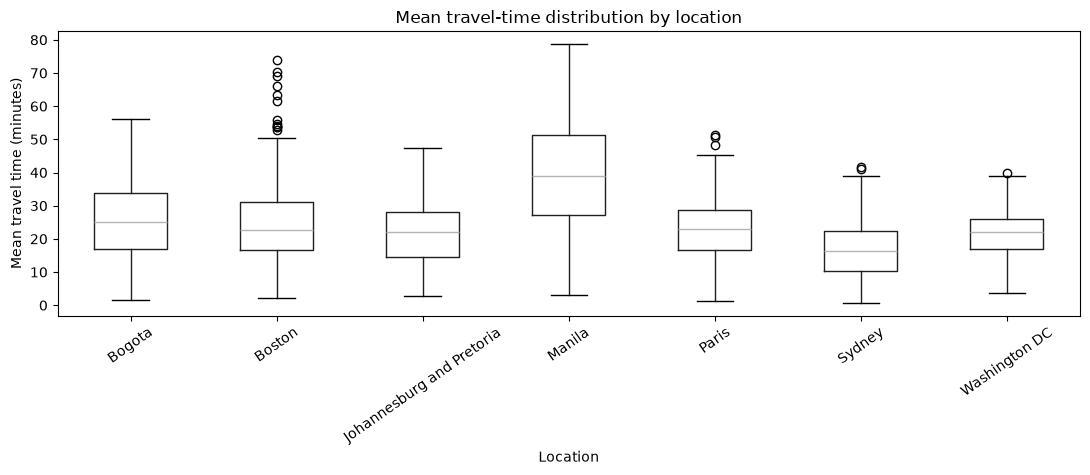

In [6]:
summary_display = location_summary.copy()
summary_display['median_mean_tt_min'] = summary_display['median_mean_tt_sec'] / 60
summary_display['p10_mean_tt_min'] = summary_display['p10_mean_tt_sec'] / 60
summary_display['p90_mean_tt_min'] = summary_display['p90_mean_tt_sec'] / 60
display(summary_display[['location','median_mean_tt_min','p10_mean_tt_min','p90_mean_tt_min']].round(2))

ax = routes.assign(mean_tt_min=routes['mean_tt']/60).boxplot(column='mean_tt_min', by='location', rot=35, figsize=(11,5), grid=False)
ax.set_title('Mean travel-time distribution by location')
ax.set_xlabel('Location')
ax.set_ylabel('Mean travel time (minutes)')
plt.suptitle('')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'travel_time_by_location.png', dpi=140, bbox_inches='tight')
plt.show()


## 6. Route-specific variability and log symmetry

For every route define:

\[
s_r = 

rac{1}{2}\ln\left(

rac{U_r}{L_r}
ight)
\]

where `L`, `M`, and `U` are the reported lower, mean, and upper travel times. We also check whether `M` is close to the geometric midpoint `sqrt(L*U)`. This determines whether a log-space simulator is well aligned with the source statistics.


,location,median_lower_ratio,median_upper_ratio,median_log_dispersion,mean_log_symmetry_error,spearman_mean_tt_vs_dispersion
0,Bogota,0.6570,1.5201,0.4194,0.0005,-0.4426
1,Boston,0.7341,1.3612,0.3087,0.0005,-0.7807
2,Johannesburg and Pretoria,0.6795,1.4706,0.3860,0.0006,-0.3426
3,Manila,0.6675,1.4975,0.4040,0.0003,-0.6262
4,Paris,0.7303,1.3687,0.3141,0.0005,-0.6513
5,Sydney,0.7337,1.3616,0.3092,0.0009,-0.8008
6,Washington DC,0.7359,1.3578,0.3063,0.0005,-0.6477


Routes with geometric midpoint within 1% of reported mean: 99.874%
Median relative symmetry error: 0.000382


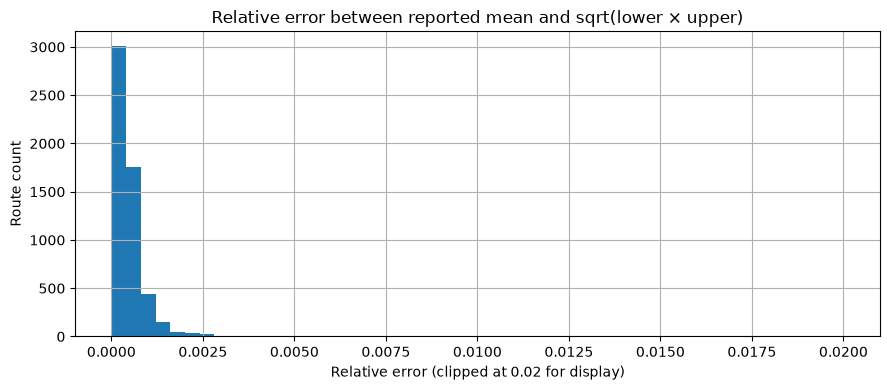

In [7]:
dispersion_table = location_summary[[
    'location','median_lower_ratio','median_upper_ratio','median_log_dispersion','mean_log_symmetry_error',
    'spearman_mean_tt_vs_dispersion'
]].copy()
display(dispersion_table.round(4))

within_1pct = (routes['log_symmetry_relative_error'] <= 0.01).mean() * 100
print(f'Routes with geometric midpoint within 1% of reported mean: {within_1pct:.3f}%')
print(f'Median relative symmetry error: {routes["log_symmetry_relative_error"].median():.6f}')

ax = routes['log_symmetry_relative_error'].clip(upper=0.02).hist(bins=50, figsize=(9,4))
ax.set_title('Relative error between reported mean and sqrt(lower × upper)')
ax.set_xlabel('Relative error (clipped at 0.02 for display)')
ax.set_ylabel('Route count')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'log_symmetry_error.png', dpi=140, bbox_inches='tight')
plt.show()


### Modeling implication

The reported range is extremely close to symmetric in log space for nearly all routes. Therefore Week 3 can generate a route observation using:

\[
T_{r,t} = M_r \exp(s_r q_{r,t})
\]

where `q=0` gives the historical mean, `q≈-1` approaches the lower bound, and `q≈+1` approaches the upper bound. This uses each route's own empirical variability instead of a single arbitrary traffic multiplier.


## 7. Geometry and distance relationship

Where both polygons are present, compute straight-line centroid distance. This is **not route distance**; it is only a geographic proxy used to understand whether absolute travel time largely reflects trip length.


,location,geometry_coverage_pct,spearman_distance_vs_mean_tt
0,Bogota,0.0,None
1,Boston,0.0,None
2,Johannesburg and Pretoria,0.0,None
3,Manila,0.0,None
4,Paris,0.0,None
5,Sydney,0.0,None
6,Washington DC,0.0,None


Rows with usable origin/destination geometry: 0 / 5,547 (0.0%)


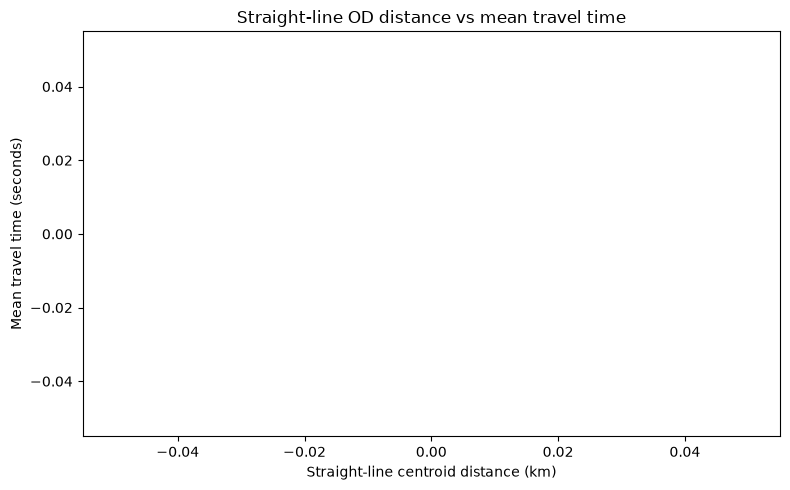

In [8]:
geo_summary = location_summary[['location','geometry_coverage_pct','spearman_distance_vs_mean_tt']]
display(geo_summary.round(3))

geo = routes.dropna(subset=['straight_line_distance_km']).copy()
print(f'Rows with usable origin/destination geometry: {len(geo):,} / {len(routes):,} ({len(geo)/len(routes)*100:.1f}%)')

ax = geo.plot.scatter(x='straight_line_distance_km', y='mean_tt', figsize=(8,5), alpha=0.25)
ax.set_title('Straight-line OD distance vs mean travel time')
ax.set_xlabel('Straight-line centroid distance (km)')
ax.set_ylabel('Mean travel time (seconds)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'distance_vs_travel_time.png', dpi=140, bbox_inches='tight')
plt.show()


**Implication:** absolute travel time should not be treated as congestion. Longer routes naturally take longer. Week 5 should use route-normalized metrics such as `current_tt / historical_mean_tt` and a normalized log-state rather than raw seconds.


## 8. Final Week 1 artifacts

Run the same reusable profiling path used by the CLI and write the contract artifacts consumed by later weeks.


In [9]:
result = write_artifacts(DATA_DIR, REPO_ROOT / 'artifacts')
print('Generated artifacts:')
for name, path in result['paths'].items():
    print(f'- {name}: {path}')

display(result['location_summary'].round(4))


Generated artifacts:
- data_profile: C:\Users\Theguywhovanish\Documents\Study\Big Data\Traffic-Density-Prediction\artifacts\data_profile.json
- file_profile: C:\Users\Theguywhovanish\Documents\Study\Big Data\Traffic-Density-Prediction\artifacts\file_profile.csv
- location_summary: C:\Users\Theguywhovanish\Documents\Study\Big Data\Traffic-Density-Prediction\artifacts\location_summary.csv
- route_statistics: C:\Users\Theguywhovanish\Documents\Study\Big Data\Traffic-Density-Prediction\artifacts\route_statistics.csv
- normalized_preview: C:\Users\Theguywhovanish\Documents\Study\Big Data\Traffic-Density-Prediction\artifacts\normalized_preview.csv


,location,rows,unique_origins,unique_destinations,median_mean_tt_sec,p10_mean_tt_sec,p90_mean_tt_sec,median_lower_ratio,median_upper_ratio,median_log_dispersion,mean_log_symmetry_error,geometry_coverage_pct,spearman_mean_tt_vs_dispersion,spearman_distance_vs_mean_tt
0,Bogota,496,1,496,1509.0,698.5,2413.5,0.6570,1.5201,0.4194,0.0005,0.0,-0.4426,None
1,Boston,700,1,700,1367.5,711.9,2301.4,0.7341,1.3612,0.3087,0.0005,0.0,-0.7807,None
2,Johannesburg and Pretoria,226,1,226,1315.5,555.0,2039.0,0.6795,1.4706,0.3860,0.0006,0.0,-0.3426,None
3,Manila,477,1,477,2337.0,1011.4,3704.2,0.6675,1.4975,0.4040,0.0003,0.0,-0.6262,None
4,Paris,2227,1,2227,1371.0,735.0,1974.0,0.7303,1.3687,0.3141,0.0005,0.0,-0.6513,None
5,Sydney,871,1,871,981.0,384.0,1716.0,0.7337,1.3616,0.3092,0.0009,0.0,-0.8008,None
6,Washington DC,550,1,550,1316.5,736.8,1823.2,0.7359,1.3578,0.3063,0.0005,0.0,-0.6477,None


## 9. Week 1 conclusions for implementation

- The supplied archive contains **7 valid city files and 5,547 valid OD rows**.
- Each file has **one unique origin and many destinations**, so we must preserve the source topology.
- The files contain **daily averages**, so hourly demand/rush-hour patterns are not learnable from this dataset.
- Lower/mean/upper values are almost perfectly log-symmetric, supporting a route-specific log-space synthetic model.
- Geometry is available for only part of the archive; geographic features must remain optional.
- Physical vehicle density is unavailable. Future streaming outputs should be described as **relative traffic pressure / congestion**, not measured vehicles per kilometer.
